# Trabalho Final de Machine Learning — Parte 1: Regressão
**Dataset 09 — Wine Quality** · Etapas 1 (análise exploratória), 2 (limpeza e pré-processamento), 3 (modelagem), 4 (avaliação) e 5 (ajuste de hiperparâmetros)

**Objetivo:** prever a nota `quality` do vinho como um número contínuo, a partir das variáveis físico-químicas.

Este notebook tem o mesmo código do arquivo `parte1_regressao.py`. A diferença é que **depois de cada saída (texto ou gráfico) tem uma explicação do que ela significa**.

## 1. Etapa 1 — Análise exploratória

### 1.1 Carga dos dados

In [1]:
# Importando as bibliotecas que vamos usar nos gráficos e na manipulação dos dados
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Carregamos o dataset em um dataframe do pandas
wine = pd.read_csv("../Docs/DataSet/group_9_winequality.csv")
print("Linhas e colunas do dataset original:", wine.shape)

Linhas e colunas do dataset original: (6497, 13)


**O que a saída significa:** o dataset original tem **6.497 vinhos (linhas)** e **13 colunas**: 11 variáveis físico-químicas, o tipo do vinho (`type`: tinto ou branco) e a nota (`quality`), que é o que queremos prever.

### 1.2 Correção dos erros do CSV
O CSV veio com erros de formato e de escala (por exemplo `density` = 2770 quando o normal é perto de 1, e uma nota `quality` = 224 quando a nota vai de 3 a 9). Se fizéssemos gráficos com esses valores, um único número absurdo estragaria o eixo inteiro. Por isso corrigimos primeiro o que tem conserto e removemos o que não tem. A cada remoção, o código imprime quantas linhas saíram.

In [2]:
# Existe 1 linha sem o tipo do vinho (type). Não dá para adivinhar se é tinto ou branco, então removemos
antes = len(wine)
wine = wine.dropna(subset=["type"])
print("Removidas por type ausente:", antes - len(wine))

# Alguns vinhos brancos aparecem como "whitewhitewhite...", vamos corrigir para "white"
wine.loc[wine["type"].str.startswith("white"), "type"] = "white"

# A nota de qualidade vai de 3 a 9: a linha com nota 224 (erro) e a sem nota (ausente) não têm conserto
antes = len(wine)
wine = wine[wine["quality"] <= 10]
print("Removidas por nota inválida:", antes - len(wine))

Removidas por type ausente: 1
Removidas por nota inválida: 2


**O que a saída significa:**
- **1 linha** saiu porque não tinha o tipo do vinho.
- **2 linhas** saíram por nota inválida: uma com nota 224 (erro de digitação) e uma sem nota nenhuma.
- O "whitewhite…" não gera linha removida, porque só corrigimos o texto para `white`.

In [3]:
# --- Coluna alcohol ---
# Tentamos converter tudo para número, o que não der certo vira NaN
alcohol_num = pd.to_numeric(wine["alcohol"], errors="coerce")
erros = alcohol_num.isna()

# Nos que falharam (ex.: "100.333.333.333.333"), tiramos os pontos e convertemos
alcohol_texto = wine.loc[erros, "alcohol"].str.replace(".", "", regex=False).astype(float)

# Juntamos os dois e dividimos por 10 até o valor ficar abaixo de 20
wine["alcohol"] = alcohol_num
wine.loc[erros, "alcohol"] = alcohol_texto
for i in range(40):
    wine.loc[wine["alcohol"] > 20, "alcohol"] = wine["alcohol"] / 10

# --- Coluna density ---
# A densidade deveria ficar perto de 1, mas veio em escalas misturadas (0.99, 9.97, 99.7, 997)
# Dividimos por 10 todos os valores maiores que 2, repetindo até ficar na escala certa
for i in range(4):
    wine.loc[wine["density"] > 2, "density"] = wine["density"] / 10

# Densidades que continuam impossíveis (fora de 0.98 a 1.04) não têm conserto, removemos
antes = len(wine)
wine = wine[(wine["density"] >= 0.98) & (wine["density"] <= 1.04)]
print("Removidas por densidade impossível:", antes - len(wine))

# --- Colunas chlorides e volatile acidity ---
# Muitos valores estão multiplicados por 1000 (ex.: 76 no lugar de 0.076)
wine.loc[wine["chlorides"] > 1, "chlorides"] = wine["chlorides"] / 1000
wine.loc[wine["volatile acidity"] > 5, "volatile acidity"] = wine["volatile acidity"] / 1000

Removidas por densidade impossível: 98


**O que a saída significa:** `alcohol`, `density`, `chlorides` e `volatile acidity` vieram em **escalas misturadas** (o mesmo vinho podia aparecer como 0,99, 9,9, 99 ou 990). O código coloca todos na escala certa, dividindo por 10 ou por 1000. Isso não remove linhas.

As **98 linhas** removidas têm densidade que continua impossível mesmo depois de corrigir a escala (ficavam em torno de 1,2, sendo que a densidade de um vinho fica entre 0,98 e 1,04). Não dá para adivinhar o valor verdadeiro, então saíram.

In [4]:
# --- Valores fisicamente impossíveis ---
# Faixa plausível de cada variável (mínimo, máximo)
faixas = {
    "fixed acidity": (3.5, 16),
    "volatile acidity": (0.05, 1.6),
    "citric acid": (0, 1.7),
    "residual sugar": (0.5, 66),
    "chlorides": (0.005, 0.62),
    "free sulfur dioxide": (1, 290),
    "total sulfur dioxide": (5, 440),
    "pH": (2.7, 4.1),
    "sulphates": (0.2, 2.0),
}

# Removemos as linhas fora da faixa (linhas com valor ausente são mantidas, tratamos depois)
antes = len(wine)
for coluna, (minimo, maximo) in faixas.items():
    fora = (wine[coluna] < minimo) | (wine[coluna] > maximo)
    wine = wine[~fora]
print("Removidas por valor fora da faixa:", antes - len(wine))

# --- Linhas duplicadas ---
# Duplicatas fazem o modelo ver o mesmo vinho várias vezes e podem
# vazar para o teste (o mesmo vinho no treino e no teste), por isso removemos
antes = len(wine)
wine = wine.drop_duplicates()
print("Removidas por duplicadas:", antes - len(wine))
print("Linhas restantes após a limpeza:", len(wine))

Removidas por valor fora da faixa: 9
Removidas por duplicadas: 1083
Linhas restantes após a limpeza: 5304


**O que a saída significa:**
- **9 linhas** tinham algum valor impossível mesmo depois das correções (por exemplo `fixed acidity` = 306, `pH` = 48, `total sulfur dioxide` = 5453). As faixas aceitas foram definidas com base em valores reais de vinhos.
- **1.083 linhas** eram duplicadas (cerca de 17% do dataset). Removemos porque o modelo veria o mesmo vinho várias vezes, e o mesmo vinho poderia cair no treino e no teste, deixando o resultado bom demais.
- Ficamos com **5.304 vinhos** para trabalhar.

Conta: 6.497 − 1 − 2 − 98 − 9 − 1.083 = 5.304.

### 1.3 Histogramas

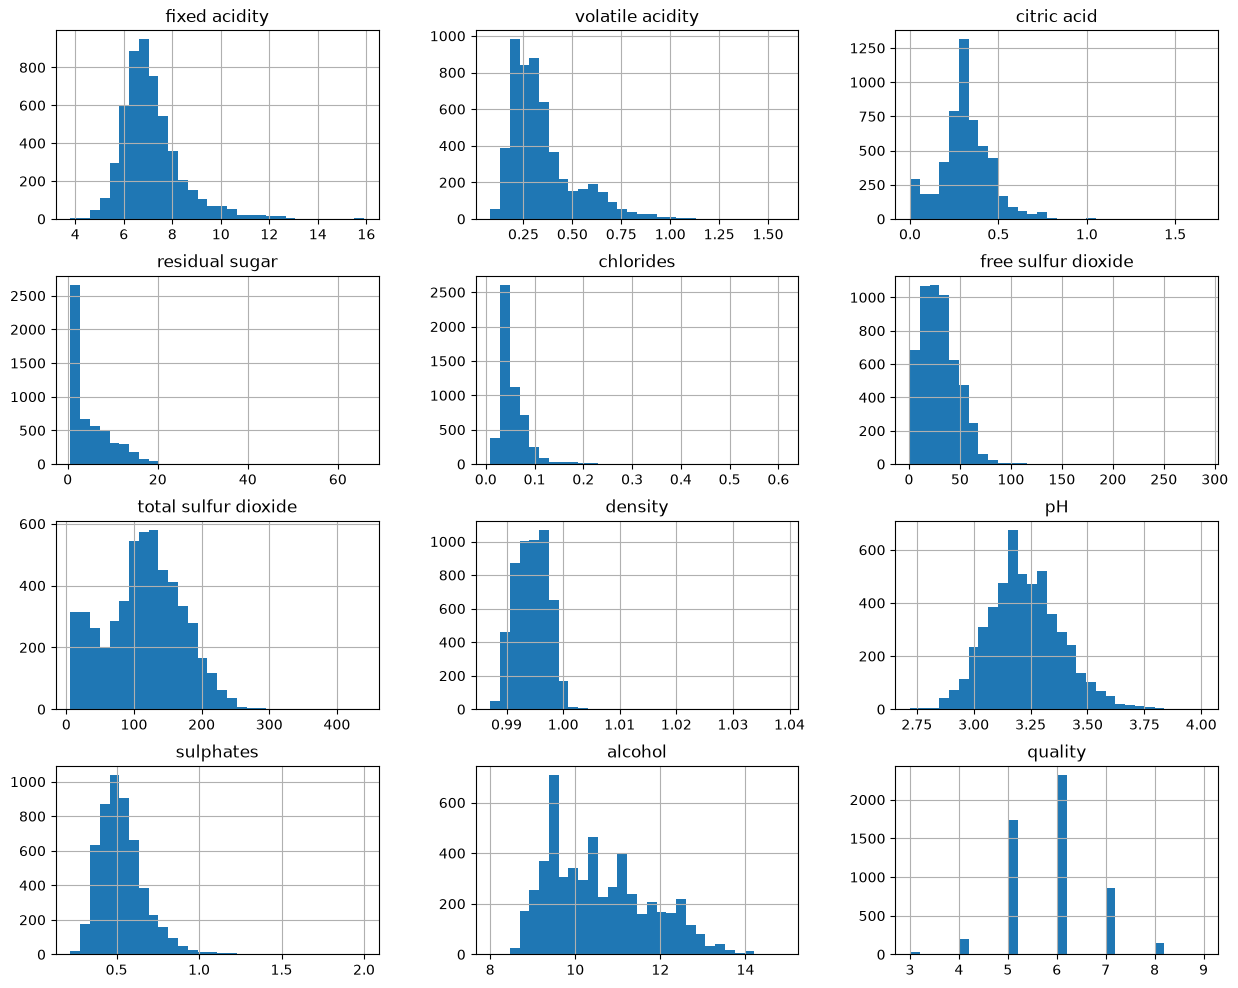

In [5]:
# Histograma de todas as colunas numéricas, para ver a distribuição de cada uma
wine.hist(bins=30, figsize=(15, 12))
plt.show()

**Como ler:** cada gráfico mostra uma variável. O eixo horizontal é o valor da variável e a altura da barra é quantos vinhos têm aquele valor.

**O que vemos:**
- **`quality` (a nota):** quase todos os vinhos têm nota **5 ou 6** (as barras mais altas), com a nota 7 logo atrás. Notas 3, 4, 8 e 9 são raras. Isso importa: o modelo vê poucos exemplos de vinho muito ruim ou muito bom, então terá dificuldade para acertar os extremos.
- **`residual sugar`, `chlorides`, `free sulfur dioxide`, `volatile acidity`, `fixed acidity` e `sulphates`:** a maioria dos vinhos fica nos valores baixos e há uma **cauda longa para a direita** (poucos vinhos com valores muito altos). Distribuições assim são chamadas de assimétricas.
- **`pH`:** tem formato de sino, bem simétrico, centrado em torno de 3,2.
- **`density`:** fica concentrada em uma faixa bem estreita (0,99 a 1,00).
- **`total sulfur dioxide`:** parece ter **dois montes** (um perto de 30 e outro perto de 130). Faz sentido: vinhos tintos e brancos têm quantidades bem diferentes desse composto.
- **`alcohol`:** tem formato irregular, com vários picos (em torno de 9,5, 10,5 e 11), e **não** parece um sino.
- **`citric acid`:** concentra-se em torno de 0,3, mas há um grupo de vinhos com valor próximo de 0.

### 1.4 Matriz de correlação
A correlação vai de −1 a +1. **Perto de +1:** quando uma variável sobe, a outra também sobe. **Perto de −1:** quando uma sobe, a outra desce. **Perto de 0:** não há relação linear.

In [6]:
# Calculamos a correlação entre as colunas numéricas
corr_matrix = wine.corr(numeric_only=True)

# Vendo quem tem maior correlação com a nota de qualidade
print("Correlação com a nota (quality):")
print(corr_matrix["quality"].sort_values(ascending=False))

Correlação com a nota (quality):
quality                 1.000000
alcohol                 0.473249
citric acid             0.101495
free sulfur dioxide     0.054787
sulphates               0.043209
pH                      0.036117
total sulfur dioxide   -0.047292
residual sugar         -0.052692
fixed acidity          -0.083518
chlorides              -0.203212
volatile acidity       -0.265047
density                -0.333152
Name: quality, dtype: float64


**O que a saída significa:** é a lista de quanto cada variável se relaciona com a nota, da mais positiva para a mais negativa.
- **`alcohol` (+0,47):** é a maior de todas. Vinhos com **mais álcool tendem a ter nota maior**.
- **`density` (−0,33)** e **`volatile acidity` (−0,27):** correlação negativa. Vinhos **mais densos** e com **mais acidez volátil** (que dá gosto de vinagre) tendem a ter nota menor.
- **`chlorides` (−0,20):** também negativa, mais fraca.
- **`citric acid`, `free sulfur dioxide`, `sulphates`, `pH`, `total sulfur dioxide`, `residual sugar` e `fixed acidity`:** perto de 0 (entre −0,08 e +0,10). Sozinhas, dizem pouco sobre a nota.
- Nenhuma correlação passa de 0,5. Por isso não esperamos que o modelo seja perfeito.

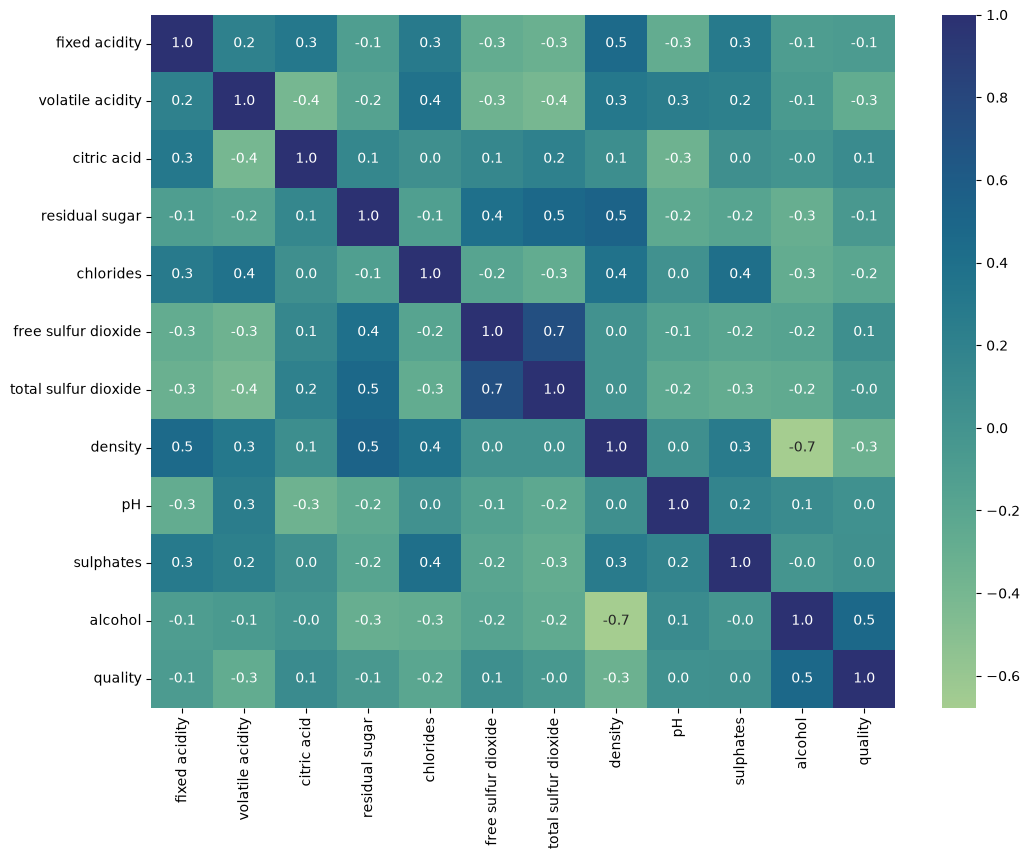

In [7]:
# Heatmap da matriz de correlação
plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix, cmap="crest", annot=True, fmt=".1f")
plt.show()

**Como ler:** é a mesma tabela de correlação, só que de todas as variáveis contra todas. Cada quadrado é o cruzamento de duas variáveis, e o número dentro é a correlação. Cores escuras indicam correlação positiva forte, e cores claras (verde-claro) indicam correlação negativa. A diagonal é sempre 1,0 (cada variável com ela mesma).

**O que vemos:**
- **A última linha (`quality`)** repete o que já vimos: `alcohol` é a mais positiva (0,5) e `density` e `volatile acidity` são as mais negativas (−0,3).
- **`alcohol` × `density` = −0,7:** forte correlação negativa. Faz sentido: o álcool é mais leve que a água, então mais álcool deixa o vinho menos denso. Isso explica por que `density` também aparece correlacionada com a nota: em parte ela só "carrega" a informação do álcool.
- **`free sulfur dioxide` × `total sulfur dioxide` = 0,7:** faz sentido, já que o total inclui o livre.
- **`residual sugar` × `density` = 0,5** e **`fixed acidity` × `density` = 0,5:** mais açúcar e mais acidez deixam o vinho mais denso.
- Quando duas variáveis de entrada são muito correlacionadas entre si (como as pares acima), dizemos que há **multicolinearidade**. Isso pode atrapalhar os coeficientes de uma regressão linear.

### 1.5 Scatter plot

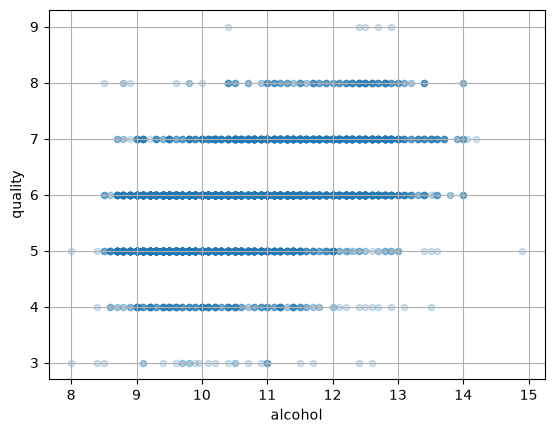

In [8]:
# Scatter plot da variável mais correlacionada (alcohol) com a nota
wine.plot(kind="scatter", x="alcohol", y="quality", alpha=0.2, grid=True)
plt.show()

**Como ler:** cada ponto é um vinho. O eixo horizontal é o teor de álcool e o vertical é a nota. Os pontos são semitransparentes (`alpha=0.2`), então onde há muitos vinhos juntos a cor fica mais escura.

**O que vemos:**
- Os pontos aparecem em **linhas horizontais** porque a nota é um número inteiro (3, 4, 5, 6, 7, 8, 9).
- Há uma **tendência**: nas notas altas (7 e 8) os pontos se deslocam para a direita (mais álcool), e nas notas baixas (4 e 5) ficam mais para a esquerda.
- Mas as linhas se **sobrepõem muito**: vinhos com o mesmo teor de álcool recebem notas bem diferentes. Isso é o que significa uma correlação de 0,47, que é moderada. O álcool ajuda a prever a nota, mas sozinho não basta.

### 1.6 Scatter plots das 4 variáveis mais correlacionadas com a nota
Na seção 1.5 olhamos só o `alcohol`. Aqui escolhemos **automaticamente** as 4 variáveis com maior correlação (em valor absoluto) com a nota e desenhamos um scatter para cada uma, com uma **reta de tendência** em vermelho.

In [ ]:
# Escolhemos as 4 variáveis com maior correlação (em valor absoluto) com a nota
top4 = corr_matrix["quality"].drop("quality").abs().sort_values(ascending=False).head(4).index

fig, eixos = plt.subplots(2, 2, figsize=(12, 8))
for ax, coluna in zip(eixos.ravel(), top4):
    sns.regplot(data=wine, x=coluna, y="quality", ax=ax,
                scatter_kws={"alpha": 0.15, "s": 10}, line_kws={"color": "red"})
    ax.set_title(f"{coluna} x quality (correlação = {corr_matrix.loc[coluna, 'quality']:.2f})")
plt.tight_layout()
plt.show()

**Como ler:** cada ponto é um vinho e a reta vermelha é a tendência linear entre a variável e a nota. O título de cada gráfico mostra a correlação já calculada na seção 1.4.

**O que observar:**
- **Inclinação da reta:** reta subindo = quanto maior a variável, maior a nota; reta descendo = o contrário.
- **Dispersão em volta da reta:** se os pontos estão muito espalhados, a variável sozinha explica pouco da nota. Com correlações abaixo de 0,5, é esperado que a nuvem de pontos seja larga.
- Como a nota é um número inteiro, os pontos formam **faixas horizontais**, como já vimos no scatter da seção 1.5.

### 1.7 Distribuição da nota por tipo de vinho
O histograma da seção 1.3 mostrou que a nota se concentra em poucos valores. Aqui detalhamos isso e separamos os vinhos **tintos** e **brancos**, porque eles têm composição química bem diferente (o `total sulfur dioxide` já mostrou dois "montes").

In [ ]:
# Quantos vinhos existem em cada nota, separando por tipo
print("Quantidade de vinhos por nota e por tipo:")
print(pd.crosstab(wine["quality"].astype(int), wine["type"]))

plt.figure(figsize=(8, 4))
sns.countplot(x=wine["quality"].astype(int), hue=wine["type"])
plt.xlabel("quality")
plt.title("Distribuição da nota de qualidade por tipo de vinho")
plt.show()

print("\nNota média por tipo:")
print(wine.groupby("type")["quality"].agg(["count", "mean", "std"]).round(2))

**O que a saída significa:** a tabela conta quantos vinhos de cada tipo receberam cada nota, e o gráfico de barras mostra a mesma informação. A última tabela resume, para cada tipo, a **quantidade**, a **nota média** e o **desvio padrão** (o quanto as notas variam em torno da média).

**Por que isso importa para o modelo:**
- Se as barras das notas extremas (3, 4, 8 e 9) são muito baixas, o modelo vê **poucos exemplos** delas e tende a errar mais nessa faixa. Voltaremos a isso na etapa 4, quando medirmos o erro por nota.
- Se um tipo tem bem menos vinhos que o outro, o modelo aprende melhor o tipo mais frequente. Por isso mantemos a coluna `type` como variável de entrada.

### 1.8 A correlação com a nota muda entre tintos e brancos?
Uma correlação calculada com todos os vinhos juntos pode esconder diferenças entre os grupos. Calculamos a correlação com a nota separadamente para cada tipo.

In [ ]:
# Correlação de cada variável com a nota, calculada separadamente para cada tipo
corr_por_tipo = pd.DataFrame({
    tipo: wine[wine["type"] == tipo].corr(numeric_only=True)["quality"]
    for tipo in wine["type"].unique()
}).drop("quality")
corr_por_tipo["geral"] = corr_matrix["quality"].drop("quality")

print("Correlação com a nota (quality) por tipo de vinho:")
print(corr_por_tipo.sort_values("geral", ascending=False).round(2))

**Como ler:** cada linha é uma variável e cada coluna é um grupo (tintos, brancos e todos juntos). Compare os sinais e os tamanhos dos números entre as colunas.

**O que observar:**
- Se uma variável tem **o mesmo sinal e tamanho parecido** nos dois tipos, ela é um bom preditor geral da nota.
- Se o sinal ou a força **muda bastante** entre os tipos, o efeito dessa variável depende do tipo de vinho. Isso justifica deixar `type` como entrada do modelo e, em modelos como a Random Forest, que capturam interações, deve ajudar.

## 2. Etapa 2 — Limpeza e pré-processamento
A correção dos erros do CSV já foi feita na seção 1.2. Aqui tratamos o que falta: valores ausentes, outliers, a coluna de texto `type` e a padronização.

### 2.1 Valores ausentes

In [9]:
# Quantos valores ausentes temos em cada coluna? (mostramos só as que têm)
ausentes = wine.isnull().sum()
print("Valores ausentes antes de tratar:")
print(ausentes[ausentes > 0])

# Separamos as colunas numéricas
from sklearn.impute import SimpleImputer

wine_num = wine.select_dtypes(include=[np.number])

# O imputer vai calcular a mediana de cada coluna e preencher onde está faltando
imputer = SimpleImputer(strategy="median")
imputer.fit(wine_num)
X = imputer.transform(wine_num)

# O imputer devolve um array do numpy, voltamos para um dataframe do pandas
wine_num = pd.DataFrame(X, columns=wine_num.columns, index=wine_num.index)

Valores ausentes antes de tratar:
fixed acidity             1
volatile acidity          1
citric acid               1
residual sugar            1
chlorides                 1
free sulfur dioxide       1
total sulfur dioxide      1
pH                      162
sulphates                 1
alcohol                   1
dtype: int64


**O que a saída significa:** a lista mostra quantos valores faltam em cada coluna. O **`pH` tem 162 valores ausentes** (cerca de 3% dos vinhos) e as demais colunas têm **só 1** cada.

Em vez de jogar fora esses vinhos, **preenchemos o buraco com a mediana** da coluna (o valor do meio). Usamos a mediana, e não a média, porque ela não é puxada por valores extremos. Depois dessa célula não há mais valores ausentes.

### 2.2 Detecção de outliers
Outliers são valores muito afastados do resto. Usamos o método do **IQR**: calculamos o intervalo onde ficam os 50% centrais dos dados (entre o 1º e o 3º quartil, Q1 e Q3) e consideramos outlier quem estiver mais de 1,5 vezes essa largura para fora.

In [10]:
# Detectando outliers pelo método do IQR (Q3 - Q1): valor fora de 1.5 x IQR dos quartis
# Os que sobraram depois da limpeza são vinhos reais (variação natural), por isso mantemos
print("Outliers por coluna (IQR):")
for coluna in wine_num.columns.drop("quality"):
    q1 = wine_num[coluna].quantile(0.25)
    q3 = wine_num[coluna].quantile(0.75)
    iqr = q3 - q1
    outliers = (wine_num[coluna] < q1 - 1.5 * iqr) | (wine_num[coluna] > q3 + 1.5 * iqr)
    print(coluna, ":", outliers.sum())

Outliers por coluna (IQR):
fixed acidity : 267
volatile acidity : 277
citric acid : 332
residual sugar : 124
chlorides : 234
free sulfur dioxide : 52
total sulfur dioxide : 11
density : 3
pH : 78
sulphates : 159
alcohol : 1


**O que a saída significa:** é quantos vinhos cada variável marca como outlier. As colunas com mais outliers são `citric acid` (332), `volatile acidity` (277), `fixed acidity` (267), `chlorides` (234) e `sulphates` (159). Combina com os histogramas: são justamente as variáveis com **cauda longa à direita**. `density` e `alcohol` quase não têm (3 e 1).

**Decisão: mantemos esses outliers.** Os erros absurdos de digitação (como 2770 em `density`) já foram corrigidos ou removidos na seção 1.2. O que sobrou são vinhos reais com valores altos, por exemplo um vinho doce com muito açúcar. Remover cortaria vinhos de verdade e perderíamos informação.

#### 2.2.1 Resumo e boxplots dos outliers
O código acima só conta os outliers. Aqui organizamos o resultado em uma tabela com **percentual** e **limites do IQR**, e desenhamos um **boxplot** de cada variável. No boxplot, a caixa vai de Q1 a Q3, o traço no meio é a mediana, e os pontos isolados são os outliers.

In [ ]:
# Tabela com a quantidade, o percentual e os limites do IQR de cada variável
resumo = []
for coluna in wine_num.columns.drop("quality"):
    q1 = wine_num[coluna].quantile(0.25)
    q3 = wine_num[coluna].quantile(0.75)
    iqr = q3 - q1
    marcados = (wine_num[coluna] < q1 - 1.5 * iqr) | (wine_num[coluna] > q3 + 1.5 * iqr)
    resumo.append({
        "variavel": coluna,
        "outliers": int(marcados.sum()),
        "percentual (%)": round(100 * marcados.mean(), 1),
        "limite inferior": round(q1 - 1.5 * iqr, 3),
        "limite superior": round(q3 + 1.5 * iqr, 3),
    })
tabela_outliers = pd.DataFrame(resumo).sort_values("outliers", ascending=False)
print(tabela_outliers.to_string(index=False))

# Boxplot de cada variável (cada uma na sua escala)
colunas = wine_num.columns.drop("quality")
fig, eixos = plt.subplots(3, 4, figsize=(16, 10))
for ax, coluna in zip(eixos.ravel(), colunas):
    sns.boxplot(y=wine_num[coluna], ax=ax)
    ax.set_title(coluna)
    ax.set_ylabel("")
for ax in eixos.ravel()[len(colunas):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

**Como ler a tabela:** `percentual (%)` é a fatia dos vinhos marcada como outlier em cada variável. `limite inferior` e `limite superior` são os valores a partir dos quais o IQR considera um vinho fora do normal. Isso permite conferir se os limites fazem sentido para o vinho (por exemplo, um limite superior de `residual sugar` coerente com vinhos doces reais).

**Como ler os boxplots:** os pontos acima da caixa formam uma fila longa nas variáveis com cauda longa à direita (os mesmos casos vistos nos histogramas). Não há pontos isolados em valores absurdos, o que confirma que a limpeza da seção 1.2 funcionou.

#### 2.2.2 Manter ou limitar os outliers? Um teste de sensibilidade
Na decisão acima mantivemos os outliers porque são vinhos reais. Para **conferir com dados** se essa escolha atrapalha, comparamos o erro dos modelos de duas formas: com os dados como estão e com os valores **limitados** aos limites do IQR (técnica chamada de *winsorização*: valores acima do limite superior passam a valer o limite, e o mesmo para o inferior).

Usamos validação cruzada de 5 partes e o **RMSE** (raiz do erro quadrático médio, na mesma unidade da nota). Menor é melhor. Este é só um teste de sensibilidade; os limites foram calculados com todos os dados, por isso o resultado não entra na avaliação final.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

X_sens = wine_num.drop(columns="quality")
y_sens = wine_num["quality"]

# Versão com os outliers limitados aos limites do IQR
q1 = X_sens.quantile(0.25)
q3 = X_sens.quantile(0.75)
iqr = q3 - q1
X_limitado = X_sens.clip(lower=q1 - 1.5 * iqr, upper=q3 + 1.5 * iqr, axis=1)

kf_sens = KFold(n_splits=5, shuffle=True, random_state=42)
modelos_sens = {
    "Regressão Linear": Pipeline([("scaler", StandardScaler()), ("modelo", LinearRegression())]),
    "Random Forest": Pipeline([("scaler", StandardScaler()),
                               ("modelo", RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))]),
}

linhas = []
for nome, modelo in modelos_sens.items():
    rmse_original = -cross_val_score(modelo, X_sens, y_sens, cv=kf_sens,
                                     scoring="neg_root_mean_squared_error").mean()
    rmse_limitado = -cross_val_score(modelo, X_limitado, y_sens, cv=kf_sens,
                                     scoring="neg_root_mean_squared_error").mean()
    linhas.append({"modelo": nome,
                   "RMSE com outliers": rmse_original,
                   "RMSE outliers limitados": rmse_limitado,
                   "diferença": rmse_limitado - rmse_original})
print("Teste de sensibilidade aos outliers (validação cruzada, 5 partes):")
print(pd.DataFrame(linhas).round(4).to_string(index=False))

**O que a saída significa:** para cada modelo, comparamos o RMSE com os dados originais e com os outliers limitados. A coluna `diferença` é o RMSE limitado menos o RMSE original: **positiva** quer dizer que limitar piorou, **negativa** que melhorou.

**Como usar esse resultado:** se a diferença for **pequena** (na casa de 0,01 ou menos), limitar os outliers não compensa e manter os vinhos como estão é a escolha mais simples e honesta. Se a diferença for grande e favorável a limitar, vale reconsiderar. Esperamos que a Random Forest seja pouco afetada, pois árvores dividem os dados por valores de corte e não se importam com a distância dos extremos, e que a Regressão Linear seja a mais sensível.

### 2.3 Transformando a coluna de texto `type` em número
Os modelos só aceitam números, e `type` é texto (`red` ou `white`).

In [11]:
# A coluna type é texto (red / white), vamos transformar em número com o OrdinalEncoder
from sklearn.preprocessing import OrdinalEncoder

ordinal_encoder = OrdinalEncoder()
type_encoded = ordinal_encoder.fit_transform(wine[["type"]])

# Adicionando de volta ao dataframe numérico
wine_num["type"] = type_encoded
print("Categorias na ordem dos números:", list(ordinal_encoder.categories_[0]))

Categorias na ordem dos números: ['red', 'white']


**O que a saída significa:** o `OrdinalEncoder` troca cada texto por um número na ordem em que aparece a lista: **`red` vira 0 e `white` vira 1**.

### 2.4 Separando treino e teste

In [12]:
# X são as variáveis de entrada e y é o que queremos prever (a nota)
X = wine_num.drop(columns="quality")
y = wine_num["quality"]

# Dividimos em 80% treino e 20% teste
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Treino:", len(X_train), "linhas | Teste:", len(X_test), "linhas")

Treino:

 4243 linhas | Teste: 1061 linhas


**O que a saída significa:** `X` são as 12 variáveis de entrada e `y` é a nota. Separamos **80% dos vinhos para o treino (4.243)** e guardamos **20% para o teste (1.061)**. O modelo aprende só com o treino, e o teste serve para ver se ele acerta vinhos que nunca viu. O `random_state=42` faz a divisão ser sempre a mesma quando rodamos de novo.

### 2.5 Padronização
As variáveis estão em escalas muito diferentes (`total sulfur dioxide` vai até centenas e `chlorides` é menor que 1). A padronização coloca todas com média 0 e desvio padrão 1. Isso é importante para o SVR e ajuda a regressão linear.

In [13]:
# Padronização: ajustamos (fit) só no treino e aplicamos nos dois
from sklearn.preprocessing import StandardScaler

std_scaler = StandardScaler()
X_train_scaled = std_scaler.fit_transform(X_train)
X_test_scaled = std_scaler.transform(X_test)

Essa célula não imprime nada. O ponto importante é que o `fit` (aprender a média e o desvio) é feito **só com o treino**, e o teste só recebe a transformação. Assim nenhuma informação do teste "vaza" para o modelo.

## 3. Etapa 3 — Modelagem
Treinamos três modelos de regressão vistos em aula. Em todos o processo é o mesmo: criar o modelo, treinar com `.fit()` nos dados de treino e prever com `.predict()` nos dados de teste.
- **Regressão Linear:** o modelo mais simples, aprende uma soma ponderada das variáveis. Serve de referência.
- **SVR:** Support Vector Regression, com kernel `rbf`, que consegue aprender curvas.
- **Random Forest:** muitas árvores de decisão que votam juntas.

In [14]:
# --- Modelo 1 - Regressão Linear ---
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)
y_pred_lin = lin_reg.predict(X_test_scaled)

# --- Modelo 2 - SVR ---
from sklearn.svm import SVR

svr = SVR(kernel="rbf")
svr.fit(X_train_scaled, y_train)
y_pred_svr = svr.predict(X_test_scaled)

# --- Modelo 3 - Random Forest ---
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(random_state=42)
rf.fit(X_train_scaled, y_train)
y_pred_rf = rf.predict(X_test_scaled)

# Mostramos as 5 primeiras predições de cada modelo ao lado da nota real
print("Primeiras 5 predições (nota real x modelos):")
resultado = pd.DataFrame({
    "real": y_test.values[:5],
    "linear": y_pred_lin[:5].round(2),
    "svr": y_pred_svr[:5].round(2),
    "random_forest": y_pred_rf[:5].round(2),
})
print(resultado)

Primeiras 5 predições (nota real x modelos):
   real  linear   svr  random_forest
0   5.0    5.06  5.14           5.32
1   5.0    5.46  5.39           5.44
2   6.0    6.14  6.25           6.16
3   6.0    5.60  5.68           5.92
4   5.0    5.49  5.47           5.69


**O que a saída significa:** cada linha é um vinho do conjunto de teste. A coluna `real` é a nota que ele de fato recebeu, e as outras são o que cada modelo previu. Como é regressão, a previsão é um **número contínuo** (por exemplo 5,06), e não uma nota inteira.

Nessas 5 amostras os três modelos ficam **perto da nota real** (erros de poucos décimos), e as previsões ficam sempre na faixa de 5 a 6. Isso combina com o histograma da nota: como quase todos os vinhos têm 5 ou 6, o modelo aprende a "apostar" nessa região e dificilmente prevê notas extremas como 3 ou 9.

**Importante:** 5 amostras não servem para dizer qual modelo é melhor. Medir isso com métricas (RMSE, MAE e R²) é a etapa 4, logo abaixo.

## 4. Etapa 4 — Avaliação
Na etapa 3 vimos só 5 previsões. Para saber **qual modelo é melhor** precisamos de métricas calculadas em todos os vinhos de teste. Usamos três:

- **RMSE** (raiz do erro quadrático médio): o erro típico do modelo, na **mesma unidade da nota** (pontos). Como os erros são elevados ao quadrado antes da média, erros grandes pesam mais. Menor é melhor.
- **MAE** (erro absoluto médio): média de quanto o modelo erra, sem dar peso extra aos erros grandes. Menor é melhor.
- **R²**: fração da variação da nota que o modelo consegue explicar. **0** equivale a sempre prever a média; **1** é perfeito; pode ser **negativo** se o modelo for pior que a média.

Também treinamos um **baseline** (sempre prever a média das notas do treino). Ele não aprende nada, e serve de piso: um modelo só vale a pena se for claramente melhor que ele.

### 4.1 Métricas no conjunto de teste

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.dummy import DummyRegressor

def avaliar(nome, y_real, y_previsto):
    # Calcula as três métricas de um modelo
    return {
        "modelo": nome,
        "RMSE": np.sqrt(mean_squared_error(y_real, y_previsto)),
        "MAE": mean_absolute_error(y_real, y_previsto),
        "R²": r2_score(y_real, y_previsto),
    }

# Baseline: prevê sempre a média das notas do treino
dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train_scaled, y_train)
y_pred_dummy = dummy.predict(X_test_scaled)

previsoes = {
    "Baseline (média)": y_pred_dummy,
    "Regressão Linear": y_pred_lin,
    "SVR": y_pred_svr,
    "Random Forest": y_pred_rf,
}

resultados_teste = pd.DataFrame(
    [avaliar(nome, y_test, pred) for nome, pred in previsoes.items()]
).set_index("modelo")
print("Métricas no conjunto de teste:")
print(resultados_teste.round(3))

melhor_modelo = resultados_teste.drop("Baseline (média)")["RMSE"].idxmin()
print(f"\nMelhor modelo no teste (menor RMSE): {melhor_modelo}")

**Como ler:** cada linha é um modelo e cada coluna é uma métrica calculada nos vinhos de teste (que o modelo nunca viu). Compare sempre com a linha do **baseline**: o RMSE do baseline é aproximadamente o desvio padrão da nota, e o R² dele fica perto de 0.

**O que observar:**
- A distância entre o baseline e cada modelo mostra **quanto o modelo realmente aprendeu**.
- O RMSE vem em pontos de nota. Um RMSE de 0,7, por exemplo, quer dizer que o modelo erra a nota em torno de 0,7 ponto, numa escala em que quase todos os vinhos têm 5 ou 6.
- A última linha impressa indica o melhor modelo pelo RMSE.

### 4.2 Treino x teste: o modelo decorou os dados?
Se o R² no treino for **muito maior** que no teste, o modelo está **decorando** os exemplos (overfitting) em vez de aprender o padrão. Comparamos os dois.

In [ ]:
modelos_treinados = {"Regressão Linear": lin_reg, "SVR": svr, "Random Forest": rf}

linhas = []
for nome, modelo in modelos_treinados.items():
    r2_treino = r2_score(y_train, modelo.predict(X_train_scaled))
    r2_teste = resultados_teste.loc[nome, "R²"]
    linhas.append({"modelo": nome, "R² treino": r2_treino, "R² teste": r2_teste,
                   "diferença": r2_treino - r2_teste})
print("R² no treino x R² no teste:")
print(pd.DataFrame(linhas).set_index("modelo").round(3))

**Como ler:** a coluna `diferença` é o R² do treino menos o R² do teste. Quanto maior, mais o modelo se ajustou aos vinhos do treino sem conseguir repetir o desempenho em vinhos novos.

- A **Regressão Linear** é simples e costuma ter diferença pequena (é difícil ela decorar).
- A **Random Forest** com os parâmetros padrão cresce árvores até o fim, e por isso é a candidata a ter a maior diferença. Se isso acontecer, é um bom motivo para ajustar hiperparâmetros como `max_depth` e `min_samples_leaf` na etapa 5.

### 4.3 Validação cruzada
Uma única divisão treino/teste pode ser sorte ou azar. A **validação cruzada** divide o treino em 5 partes, treina em 4 e testa na restante, repetindo 5 vezes. O resultado é a média das 5 notas e o **desvio padrão**, que mostra a estabilidade do modelo.

Para não vazar informação, a padronização entra dentro de um `Pipeline`: a média e o desvio são calculados só com as 4 partes de treino de cada rodada. Usamos apenas o conjunto de **treino** aqui, o teste continua guardado.

In [ ]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline

kf = KFold(n_splits=5, shuffle=True, random_state=42)

modelos_cv = {
    "Regressão Linear": Pipeline([("scaler", StandardScaler()), ("modelo", LinearRegression())]),
    "SVR": Pipeline([("scaler", StandardScaler()), ("modelo", SVR(kernel="rbf"))]),
    "Random Forest": Pipeline([("scaler", StandardScaler()),
                               ("modelo", RandomForestRegressor(random_state=42, n_jobs=-1))]),
}

linhas = []
for nome, modelo in modelos_cv.items():
    cv = cross_validate(modelo, X_train, y_train, cv=kf,
                        scoring={"rmse": "neg_root_mean_squared_error",
                                 "mae": "neg_mean_absolute_error",
                                 "r2": "r2"})
    linhas.append({
        "modelo": nome,
        "RMSE (média)": -cv["test_rmse"].mean(),
        "RMSE (desvio)": cv["test_rmse"].std(),
        "MAE (média)": -cv["test_mae"].mean(),
        "R² (média)": cv["test_r2"].mean(),
        "R² (desvio)": cv["test_r2"].std(),
    })
resultados_cv = pd.DataFrame(linhas).set_index("modelo")
print("Validação cruzada (5 partes) no conjunto de treino:")
print(resultados_cv.round(3))

**Como ler:** as colunas de média dizem o desempenho esperado do modelo; as de desvio dizem **o quanto ele oscila** de uma parte para outra. Um desvio pequeno indica um resultado estável.

**O que observar:** se o ranking dos modelos aqui for o mesmo da seção 4.1, a conclusão não depende de uma divisão específica dos dados. Se for diferente, desconfie da comparação feita só no teste.

### 4.4 Real x previsto e resíduos
As métricas resumem tudo em um número. Os gráficos abaixo mostram **onde** os modelos acertam e erram.

- **Real x previsto:** cada ponto é um vinho de teste. Quanto mais perto da linha tracejada (previsão = nota real), melhor.
- **Resíduos** (nota real menos previsão): o ideal é uma curva em forma de sino, centrada em 0.

In [ ]:
modelos_plot = {nome: previsoes[nome] for nome in ["Regressão Linear", "SVR", "Random Forest"]}

fig, eixos = plt.subplots(2, 3, figsize=(16, 9))
for coluna, (nome, pred) in enumerate(modelos_plot.items()):
    # Linha de cima: real x previsto
    ax = eixos[0, coluna]
    ax.scatter(y_test, pred, alpha=0.25, s=12)
    ax.plot([3, 9], [3, 9], "--", color="red")
    ax.set_title(f"{nome}: real x previsto")
    ax.set_xlabel("nota real")
    ax.set_ylabel("nota prevista")

    # Linha de baixo: histograma dos resíduos
    ax = eixos[1, coluna]
    residuos = y_test.values - pred
    ax.hist(residuos, bins=30)
    ax.axvline(0, color="red", linestyle="--")
    ax.set_title(f"{nome}: resíduos (média = {residuos.mean():.2f})")
    ax.set_xlabel("nota real - nota prevista")
plt.tight_layout()
plt.show()

**Como ler o real x previsto:** se o modelo fosse perfeito, os pontos ficariam todos sobre a linha tracejada. Na prática, as previsões ficam **espremidas na faixa central** (perto de 5 e 6), enquanto as notas reais vão de 3 a 9. Isso é o efeito de a maioria dos vinhos ter nota 5 ou 6: o modelo aprende a "apostar no meio" e **subestima as notas altas e superestima as baixas**.

**Como ler os resíduos:** o histograma deve ficar centrado em 0 (modelo sem viés). Uma cauda longa para um dos lados indica vinhos que o modelo erra muito, quase sempre os de nota extrema.

### 4.5 Onde o melhor modelo erra mais? Erro por nota
Calculamos o erro absoluto médio **para cada nota real**, usando o melhor modelo da seção 4.1.

In [ ]:
pred_melhor = previsoes[melhor_modelo]
erro_por_nota = (
    pd.DataFrame({"nota_real": y_test.values.astype(int),
                  "erro_absoluto": np.abs(y_test.values - pred_melhor)})
    .groupby("nota_real")["erro_absoluto"]
    .agg(quantidade="count", erro_medio="mean")
)
print(f"Erro absoluto médio por nota real ({melhor_modelo}):")
print(erro_por_nota.round(3))

erro_por_nota["erro_medio"].plot(kind="bar", figsize=(7, 4))
plt.ylabel("erro absoluto médio (pontos)")
plt.title(f"Erro por nota real - {melhor_modelo}")
plt.show()

**Como ler:** cada linha é uma nota real, com a quantidade de vinhos de teste que a têm e o erro médio do modelo nesses vinhos. O gráfico mostra o mesmo erro em barras.

**O que observar:** o erro costuma ser **menor nas notas 5 e 6** (onde há muitos exemplos e onde o modelo "aposta") e **maior nas notas extremas** (poucos exemplos, e o modelo quase nunca prevê esses valores). Isso confirma o que o histograma da nota já indicava na etapa 1 e é uma **limitação** do modelo que deve constar na discussão.

## 5. Etapa 5 — Ajuste de hiperparâmetros
Até aqui usamos os **hiperparâmetros padrão** de cada modelo (por exemplo, `C=1` no SVR). Hiperparâmetros são configurações que não são aprendidas com os dados, e sim escolhidas por nós. Para escolher bem, testamos várias combinações e comparamos o desempenho de cada uma por **validação cruzada**.

Usamos dois métodos do scikit-learn:
- **`GridSearchCV`:** testa **todas** as combinações de uma grade de valores. Bom quando há poucas combinações.
- **`RandomizedSearchCV`:** sorteia um número fixo de combinações dentro dos intervalos. Bom quando há muitas combinações possíveis, como na Random Forest.

**Cuidados:**
- A padronização vai dentro de um `Pipeline`, para ser recalculada em cada rodada da validação cruzada (sem vazar informação).
- O critério é o **RMSE** da validação cruzada, calculado **só no treino**. O conjunto de teste só é usado no final, para comparar o antes e o depois.
- Incluímos a **Ridge**, uma regressão linear com penalização nos coeficientes (parâmetro `alpha`). Ela ajuda quando há variáveis muito correlacionadas entre si, como vimos entre `alcohol` e `density`.

### 5.1 Busca nos três modelos

In [ ]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import Ridge
from scipy.stats import randint

kf = KFold(n_splits=5, shuffle=True, random_state=42)

# --- Ridge: GridSearchCV (poucos valores, testamos todos) ---
pipe_ridge = Pipeline([("scaler", StandardScaler()), ("modelo", Ridge())])
grade_ridge = {"modelo__alpha": [0.01, 0.1, 1, 10, 100, 1000]}
busca_ridge = GridSearchCV(pipe_ridge, grade_ridge, cv=kf,
                           scoring="neg_root_mean_squared_error", n_jobs=-1)
busca_ridge.fit(X_train, y_train)

# --- SVR: GridSearchCV (5 x 3 x 2 = 30 combinações) ---
pipe_svr = Pipeline([("scaler", StandardScaler()), ("modelo", SVR(kernel="rbf"))])
grade_svr = {
    "modelo__C": [0.5, 1, 2, 5, 10],
    "modelo__gamma": [0.02, 0.05, "scale"],
    "modelo__epsilon": [0.1, 0.2],
}
busca_svr = GridSearchCV(pipe_svr, grade_svr, cv=kf,
                         scoring="neg_root_mean_squared_error", n_jobs=-1)
busca_svr.fit(X_train, y_train)

# --- Random Forest: RandomizedSearchCV (20 combinações sorteadas) ---
pipe_rf = Pipeline([("scaler", StandardScaler()),
                    ("modelo", RandomForestRegressor(random_state=42))])
espaco_rf = {
    "modelo__n_estimators": randint(100, 500),
    "modelo__max_depth": [None, 10, 15, 20, 30],
    "modelo__min_samples_leaf": randint(1, 6),
    "modelo__max_features": ["sqrt", "log2", 0.5, 1.0],
}
busca_rf = RandomizedSearchCV(pipe_rf, espaco_rf, n_iter=20, cv=kf,
                              scoring="neg_root_mean_squared_error",
                              n_jobs=-1, random_state=42)
busca_rf.fit(X_train, y_train)

# Resumo: melhor RMSE na validação cruzada e melhores parâmetros
for nome, busca in [("Ridge", busca_ridge), ("SVR", busca_svr), ("Random Forest", busca_rf)]:
    print(f"{nome}: melhor RMSE na validação cruzada = {-busca.best_score_:.4f}")
    print("   melhores parâmetros:", busca.best_params_)

**O que a saída significa:** para cada modelo, o código mostra o **menor RMSE** encontrado na validação cruzada e a **combinação de parâmetros** que o produziu. Esses são os hiperparâmetros que usaremos nos modelos finais.

**Detalhe importante:** os parâmetros vêm com o prefixo `modelo__` porque o modelo está dentro de um `Pipeline` (o `modelo` é o nome que demos ao passo). Se a melhor combinação ficar **na borda da grade** (por exemplo, o maior valor de `C` testado), vale ampliar a grade nessa direção e testar de novo.

### 5.2 As melhores combinações do SVR
Olhar só o vencedor esconde se o resultado é **sensível** aos parâmetros. Abaixo estão as 5 melhores combinações do SVR.

In [ ]:
cv_svr = pd.DataFrame(busca_svr.cv_results_)
cv_svr["RMSE (média)"] = -cv_svr["mean_test_score"]
cv_svr["RMSE (desvio)"] = cv_svr["std_test_score"]

top5_svr = cv_svr.sort_values("rank_test_score").head(5)[
    ["param_modelo__C", "param_modelo__gamma", "param_modelo__epsilon", "RMSE (média)", "RMSE (desvio)"]
]
print("5 melhores combinações do SVR:")
print(top5_svr.round(4).to_string(index=False))

**Como ler:** cada linha é uma combinação de `C`, `gamma` e `epsilon`, ordenadas do menor para o maior RMSE.

**O que observar:** se as 5 linhas têm RMSE **quase iguais**, o SVR é pouco sensível a esses parâmetros e qualquer uma delas serve. Se há uma diferença grande entre a 1ª e a 5ª, a escolha dos parâmetros pesa e o ajuste valeu a pena.
- `C` controla o quanto o modelo pune erros: valores altos ajustam mais aos dados (risco de overfitting).
- `gamma` controla o alcance de cada ponto no kernel: valores altos deixam a curva mais "recortada".
- `epsilon` é a margem de erro que o modelo tolera sem punir.

### 5.3 Antes x depois no conjunto de teste
Agora sim usamos o conjunto de teste: comparamos os modelos com parâmetros **padrão** (etapa 4) com os **ajustados**. O teste não foi usado para escolher nada, então a comparação é justa.

In [ ]:
modelos_tunados = {
    "Ridge (ajustada)": busca_ridge.best_estimator_,
    "SVR (ajustado)": busca_svr.best_estimator_,
    "Random Forest (ajustada)": busca_rf.best_estimator_,
}

previsoes_tunadas = {nome: modelo.predict(X_test) for nome, modelo in modelos_tunados.items()}
resultados_tunados = pd.DataFrame(
    [avaliar(nome, y_test, pred) for nome, pred in previsoes_tunadas.items()]
).set_index("modelo")

comparacao = pd.concat([resultados_teste, resultados_tunados])
print("Comparação final no conjunto de teste:")
print(comparacao.round(3))

# Quanto o ajuste mudou o RMSE de cada modelo
for padrao, ajustado in [("SVR", "SVR (ajustado)"), ("Random Forest", "Random Forest (ajustada)")]:
    antes = comparacao.loc[padrao, "RMSE"]
    depois = comparacao.loc[ajustado, "RMSE"]
    print(f"{padrao}: RMSE {antes:.4f} -> {depois:.4f} (variação {depois - antes:+.4f})")

comparacao["RMSE"].sort_values(ascending=False).plot(kind="barh", figsize=(8, 4))
plt.xlabel("RMSE no teste (menor é melhor)")
plt.title("Todos os modelos: RMSE no conjunto de teste")
plt.tight_layout()
plt.show()

**Como ler:** a tabela junta, no mesmo lugar, o baseline, os três modelos com parâmetros padrão e os três ajustados. As linhas impressas abaixo dela dizem quanto o RMSE mudou com o ajuste (**variação negativa = melhorou**). O gráfico de barras ordena todos pelo RMSE.

**O que observar:**
- O ganho do ajuste costuma ser **pequeno** quando os parâmetros padrão já são razoáveis. Isso não é fracasso: mostra que o desempenho é limitado pelos **dados** (variáveis que não explicam toda a nota), não pela configuração do modelo.
- Se a variação for positiva (piorou) no teste, mesmo com a validação cruzada tendo melhorado, a diferença está dentro do ruído de uma única divisão de teste.